<a href="https://colab.research.google.com/github/Deepak202545/TEST-CLASSIFICATION-BATTLE/blob/main/testclassificationbattle.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install pandas numpy scikit-learn matplotlib seaborn

       TEXT CLASSIFICATION BATTLE
       EMAIL SPAM DETECTION

Dataset downloaded successfully!

Dataset loaded successfully!
Original dataset shape: (5572, 2)

Cleaned dataset shape: (5169, 3)

First five records:
  label                                            message  label_num
0   ham  Go until jurong point, crazy.. Available only ...          0
1   ham                      Ok lar... Joking wif u oni...          0
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...          1
3   ham  U dun say so early hor... U c already then say...          0
4   ham  Nah I don't think he goes to usf, he lives aro...          0

DATASET ANALYSIS

Class Distribution:
label
ham     4516
spam     653
Name: count, dtype: int64

Total Messages: 5169
Ham Messages: 4516
Spam Messages: 653

Class Percentages:
label
ham     87.366996
spam    12.633004
Name: proportion, dtype: float64


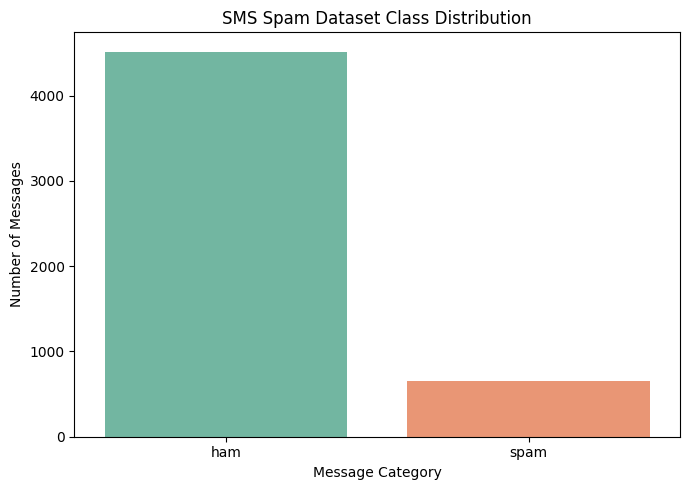


TEXT PREPROCESSING

Original Message:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

Preprocessed Message:
jurong point crazi avail bugi great world la buffet cine got amor wat

TRAIN TEST SPLIT
Training Samples: 4135
Testing Samples: 1034

TF-IDF FEATURE EXTRACTION
TF-IDF extraction completed!
Training Matrix Shape: (4135, 10000)
Testing Matrix Shape: (1034, 10000)
Number of TF-IDF Features: 10000

TRAINING MACHINE LEARNING MODELS

Training: Decision Tree
Decision Tree training completed!
Accuracy: 0.9632
Precision: 0.9043
Recall: 0.7939
F1-score: 0.8455

Training: KNN
KNN training completed!
Accuracy: 0.971
Precision: 0.972
Recall: 0.7939
F1-score: 0.8739

Training: SVM
SVM training completed!
Accuracy: 0.9807
Precision: 0.9587
Recall: 0.8855
F1-score: 0.9206

Training: Naive Bayes
Naive Bayes training completed!
Accuracy: 0.9632
Precision: 1.0
Recall: 0.7099
F1-score: 0.8304

COMPARATIVE PERFORMANCE RESULTS
    Algor

<Figure size 1200x700 with 0 Axes>

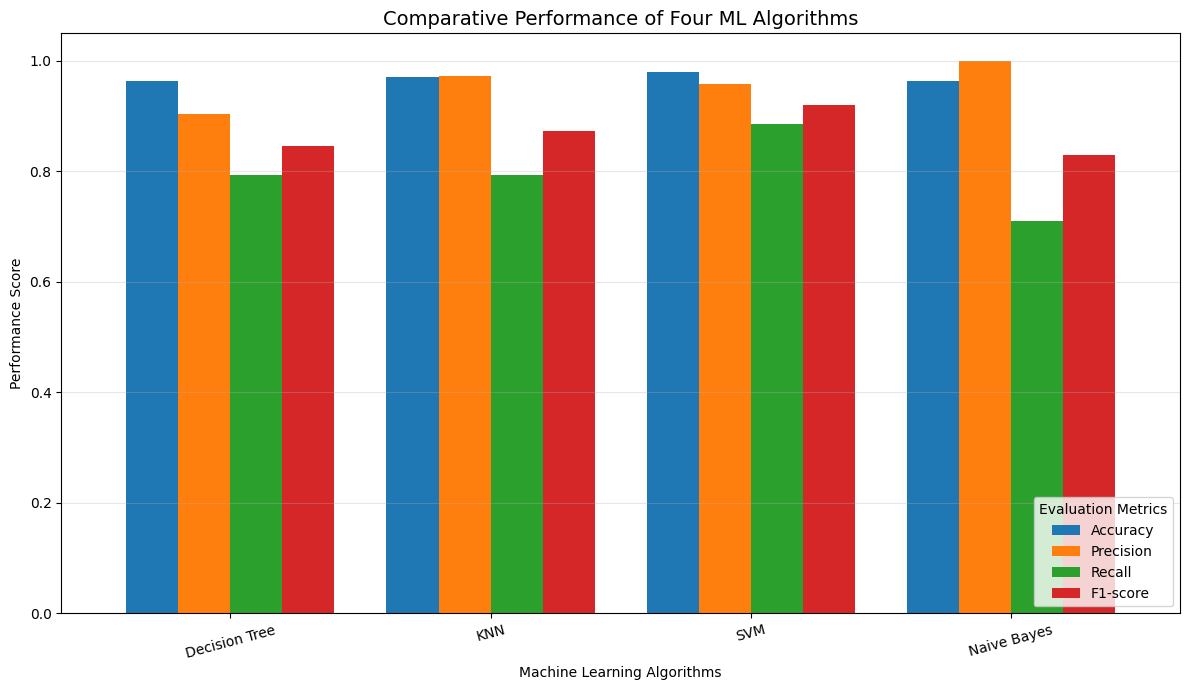


CONFUSION MATRIX ANALYSIS

Confusion Matrix: Decision Tree
[[892  11]
 [ 27 104]]


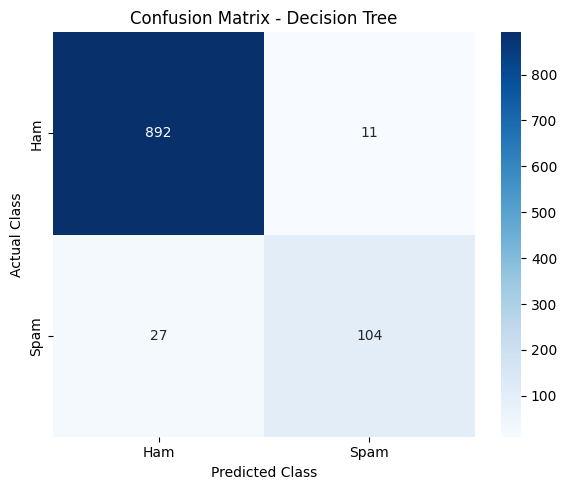


Confusion Matrix: KNN
[[900   3]
 [ 27 104]]


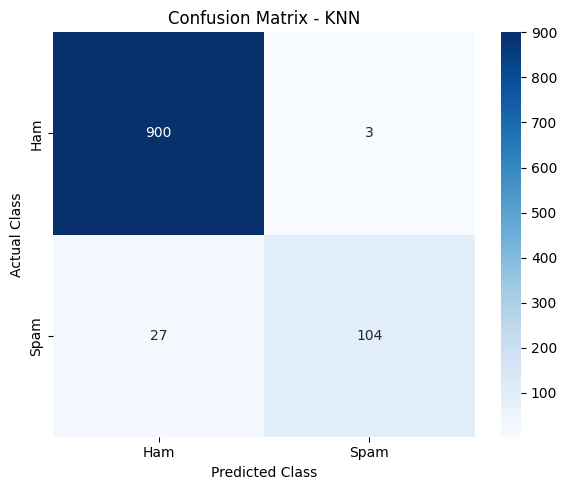


Confusion Matrix: SVM
[[898   5]
 [ 15 116]]


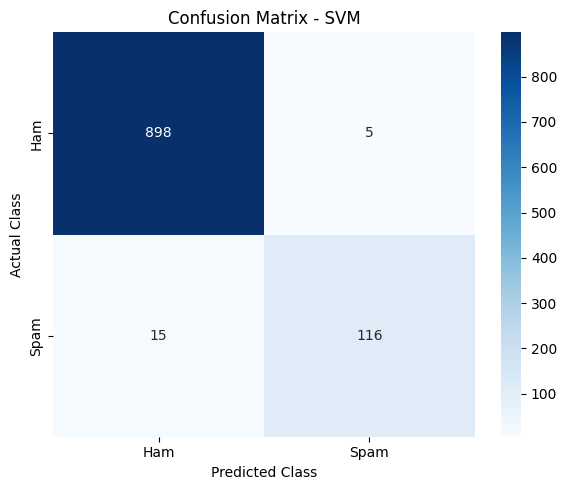


Confusion Matrix: Naive Bayes
[[903   0]
 [ 38  93]]


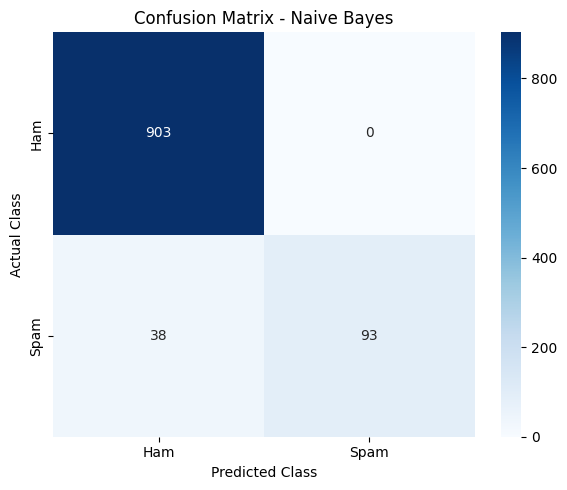


CLASSIFICATION REPORTS

 Decision Tree
              precision    recall  f1-score   support

         Ham       0.97      0.99      0.98       903
        Spam       0.90      0.79      0.85       131

    accuracy                           0.96      1034
   macro avg       0.94      0.89      0.91      1034
weighted avg       0.96      0.96      0.96      1034


 KNN
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       903
        Spam       0.97      0.79      0.87       131

    accuracy                           0.97      1034
   macro avg       0.97      0.90      0.93      1034
weighted avg       0.97      0.97      0.97      1034


 SVM
              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       903
        Spam       0.96      0.89      0.92       131

    accuracy                           0.98      1034
   macro avg       0.97      0.94      0.95      1034
weighted avg       0.9

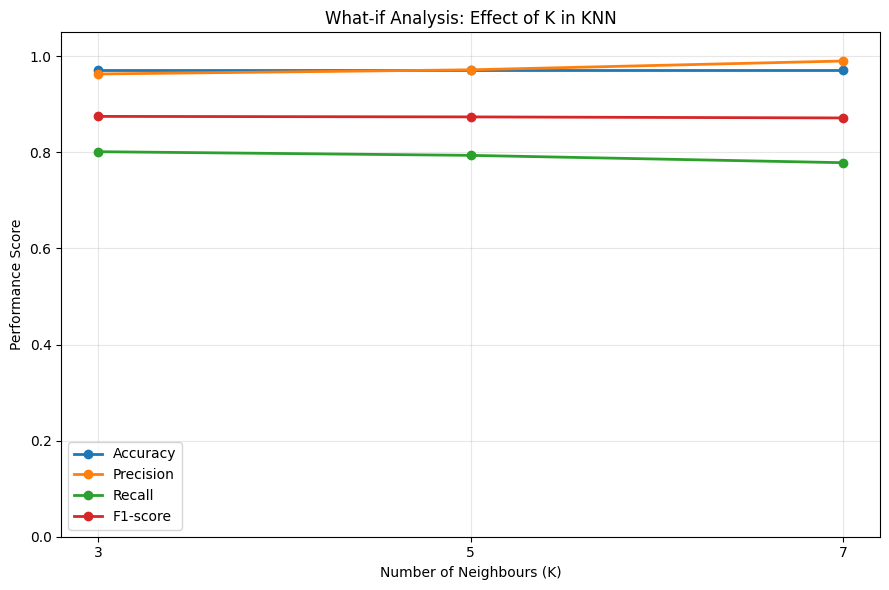


BEST-PERFORMING MODEL
Best Algorithm: SVM
Accuracy: 0.9807
Precision: 0.9587
Recall: 0.8855
F1-score: 0.9206

CUSTOM MESSAGE TESTING

Message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM

Message: Hello, are you coming to college tomorrow?
Prediction: HAM

Message: URGENT! Claim your cash reward now!
Prediction: SPAM

Message: Please send me the assignment notes.
Prediction: HAM

Message: You have been selected for a free vacation.
Prediction: SPAM

FINAL EXPERIMENT SUMMARY

Dataset: UCI SMS Spam Collection
Total Records: 5169
Training Records: 4135
Testing Records: 1034
TF-IDF Features: 10000
Algorithms Tested: 4
Evaluation Metrics: 4
What-if K Values: [3, 5, 7]

Best Model: SVM
Best F1-score: 0.9206

All experimental results saved successfully!

Output Folder: results/

Model Folder: models/

       EXPERIMENT COMPLETED SUCCESSFULLY


In [8]:
import os
import re
import time
import zipfile
import requests
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from io import BytesIO
from pathlib import Path

from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# Create output folder
os.makedirs("results", exist_ok=True)
os.makedirs("models", exist_ok=True)

print("=" * 65)
print("       TEXT CLASSIFICATION BATTLE")
print("       EMAIL SPAM DETECTION")
print("=" * 65)




DATA_FILE = "SMSSpamCollection"

DATASET_URL = (
    "https://archive.ics.uci.edu/static/"
    "public/228/sms+spam+collection.zip"
)

if not os.path.exists(DATA_FILE):

    print("\nDownloading UCI SMS Spam Collection Dataset...")

    try:
        response = requests.get(DATASET_URL, timeout=60)
        response.raise_for_status()

        with zipfile.ZipFile(
            BytesIO(response.content)
        ) as zip_ref:

            matching_files = [
                name for name in zip_ref.namelist()
                if name.endswith("/SMSSpamCollection")
                or name == "SMSSpamCollection"
            ]

            if not matching_files:
                raise FileNotFoundError(
                    "Dataset file not found inside ZIP."
                )

            with zip_ref.open(matching_files[0]) as source:
                with open(DATA_FILE, "wb") as destination:
                    destination.write(source.read())

        print("Dataset downloaded successfully!")

    except Exception as error:
        print("Automatic download failed:", error)
        print(
            "Download the UCI dataset manually and place "
            "SMSSpamCollection in this project folder."
        )
        raise



df = pd.read_csv(
    DATA_FILE,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

print("\nDataset loaded successfully!")
print("Original dataset shape:", df.shape)


df.dropna(subset=["label", "message"], inplace=True)
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)


df = df[df["label"].isin(["ham", "spam"])].copy()
df["label_num"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

print("\nCleaned dataset shape:", df.shape)

print("\nFirst five records:")
print(df.head())




print("\n" + "=" * 65)
print("DATASET ANALYSIS")
print("=" * 65)

class_counts = df["label"].value_counts()

print("\nClass Distribution:")
print(class_counts)

print("\nTotal Messages:", len(df))
print("Ham Messages:", class_counts.get("ham", 0))
print("Spam Messages:", class_counts.get("spam", 0))

print("\nClass Percentages:")
print(df["label"].value_counts(normalize=True) * 100)



plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="label",
    hue="label",
    order=["ham", "spam"],
    palette="Set2",
    legend=False
)

plt.title("SMS Spam Dataset Class Distribution")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.tight_layout()
plt.savefig("results/class_distribution.png", dpi=300)
plt.show()


print("\n" + "=" * 65)
print("TEXT PREPROCESSING")
print("=" * 65)


stemmer = PorterStemmer()


stop_words = set(ENGLISH_STOP_WORDS)


def preprocess_text(text):


    text = str(text).lower()


    tokens = re.findall(r"\b[a-z]+\b", text)


    processed_tokens = []

    for word in tokens:

        if word not in stop_words and len(word) > 1:

            stemmed_word = stemmer.stem(word)

            processed_tokens.append(stemmed_word)

    return processed_tokens



sample_message = df["message"].iloc[0]

processed_message = preprocess_text(sample_message)

print("\nOriginal Message:")
print(sample_message)

print("\nPreprocessed Message:")
print(" ".join(processed_message))



df["processed_message"] = df["message"].apply(
    lambda x: " ".join(preprocess_text(x))
)

df[[
    "label",
    "message",
    "processed_message"
]].head(20).to_csv(
    "results/preprocessing_output.csv",
    index=False
)



print("\n" + "=" * 65)
print("TRAIN TEST SPLIT")
print("=" * 65)

X = df["processed_message"]
y = df["label_num"]


X_train_text, X_test_text, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=y
    )
)

print("Training Samples:", len(X_train_text))
print("Testing Samples:", len(X_test_text))


print("\n" + "=" * 65)
print("TF-IDF FEATURE EXTRACTION")
print("=" * 65)

vectorizer = TfidfVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False,
    ngram_range=(1, 2),
    max_features=10000,
    sublinear_tf=True
)

X_train = vectorizer.fit_transform(X_train_text)

X_test = vectorizer.transform(X_test_text)

print("TF-IDF extraction completed!")

print("Training Matrix Shape:", X_train.shape)
print("Testing Matrix Shape:", X_test.shape)

print(
    "Number of TF-IDF Features:",
    len(vectorizer.get_feature_names_out())
)

feature_names = vectorizer.get_feature_names_out()

pd.DataFrame({
    "Feature": feature_names
}).to_csv(
    "results/tfidf_features.csv",
    index=False
)



print("\n" + "=" * 65)
print("TRAINING MACHINE LEARNING MODELS")
print("=" * 65)

models = {

    "Decision Tree": DecisionTreeClassifier(
        criterion="gini",
        max_depth=100,
        min_samples_leaf=2,
        random_state=RANDOM_STATE
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute",
        weights="distance"
    ),

    "SVM": LinearSVC(
        C=1.0,
        random_state=RANDOM_STATE,
        max_iter=5000
    ),

    "Naive Bayes": MultinomialNB(
        alpha=1.0
    )
}

results = []

predictions = {}

trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    start_time = time.perf_counter()

    model.fit(X_train, y_train)

    training_time = time.perf_counter() - start_time

    prediction_start = time.perf_counter()

    y_pred = model.predict(X_test)

    prediction_time = time.perf_counter() - prediction_start

    predictions[name] = y_pred
    trained_models[name] = model

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    results.append({

        "Algorithm": name,

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1-score": f1,

        "Training Time (seconds)": training_time,

        "Prediction Time (seconds)": prediction_time
    })

    print(name, "training completed!")

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-score:", round(f1, 4))



print("\n" + "=" * 65)
print("COMPARATIVE PERFORMANCE RESULTS")
print("=" * 65)

results_df = pd.DataFrame(results)

print(
    results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


results_df.to_csv(
    "results/comparative_results.csv",
    index=False
)



metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]

plt.figure(figsize=(12, 7))

results_df.set_index("Algorithm")[metrics].plot(
    kind="bar",
    figsize=(12, 7),
    width=0.8
)

plt.title(
    "Comparative Performance of Four ML Algorithms",
    fontsize=14
)

plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Performance Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=15)

plt.legend(
    title="Evaluation Metrics",
    loc="lower right"
)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "results/comparison_graph.png",
    dpi=300
)

plt.show()



print("\n" + "=" * 65)
print("CONFUSION MATRIX ANALYSIS")
print("=" * 65)

for name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    print("\nConfusion Matrix:", name)
    print(cm)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"]
    )

    plt.title("Confusion Matrix - " + name)

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.tight_layout()

    filename = (
        name.replace(" ", "_")
        + "_confusion_matrix.png"
    )

    plt.savefig(
        "results/" + filename,
        dpi=300
    )

    plt.show()


print("\n" + "=" * 65)
print("CLASSIFICATION REPORTS")
print("=" * 65)

for name, y_pred in predictions.items():

    print("\n", name)

    report = classification_report(
        y_test,
        y_pred,
        target_names=["Ham", "Spam"],
        zero_division=0
    )

    print(report)

    with open(
        "results/" + name.replace(" ", "_")
        + "_classification_report.txt",
        "w"
    ) as file:

        file.write(report)



print("\n" + "=" * 65)
print("WHAT-IF EXPERIMENT: KNN")
print("=" * 65)

knn_results = []

k_values = [3, 5, 7]

for k in k_values:

    print("\nTesting K =", k)

    knn_model = KNeighborsClassifier(
        n_neighbors=k,
        metric="cosine",
        algorithm="brute",
        weights="distance"
    )

    knn_model.fit(X_train, y_train)

    knn_pred = knn_model.predict(X_test)

    accuracy = accuracy_score(
        y_test,
        knn_pred
    )

    precision = precision_score(
        y_test,
        knn_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        knn_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        knn_pred,
        zero_division=0
    )

    knn_results.append({

        "K Value": k,

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1-score": f1
    })

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-score:", round(f1, 4))

knn_df = pd.DataFrame(knn_results)

print("\nKNN What-if Results:")

print(
    knn_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

knn_df.to_csv(
    "results/knn_what_if_results.csv",
    index=False
)



plt.figure(figsize=(9, 6))

for metric in metrics:

    plt.plot(
        knn_df["K Value"],
        knn_df[metric],
        marker="o",
        linewidth=2,
        label=metric
    )

plt.title(
    "What-if Analysis: Effect of K in KNN"
)

plt.xlabel("Number of Neighbours (K)")
plt.ylabel("Performance Score")

plt.xticks(k_values)

plt.ylim(0, 1.05)

plt.legend()

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "results/knn_what_if_graph.png",
    dpi=300
)

plt.show()


print("\n" + "=" * 65)
print("BEST-PERFORMING MODEL")
print("=" * 65)

best_index = results_df["F1-score"].idxmax()

best_model_name = results_df.loc[
    best_index,
    "Algorithm"
]

best_accuracy = results_df.loc[
    best_index,
    "Accuracy"
]

best_precision = results_df.loc[
    best_index,
    "Precision"
]

best_recall = results_df.loc[
    best_index,
    "Recall"
]

best_f1 = results_df.loc[
    best_index,
    "F1-score"
]

print("Best Algorithm:", best_model_name)

print("Accuracy:", round(best_accuracy, 4))

print("Precision:", round(best_precision, 4))

print("Recall:", round(best_recall, 4))

print("F1-score:", round(best_f1, 4))

joblib.dump(
    trained_models[best_model_name],
    "models/best_model.pkl"
)

joblib.dump(
    vectorizer,
    "models/tfidf_vectorizer.pkl"
)

print("\n" + "=" * 65)
print("CUSTOM MESSAGE TESTING")
print("=" * 65)


def predict_message(message):

    processed = " ".join(
        preprocess_text(message)
    )

    message_vector = vectorizer.transform(
        [processed]
    )

    prediction = trained_models[
        best_model_name
    ].predict(message_vector)[0]

    if prediction == 1:
        result = "SPAM"
    else:
        result = "HAM"

    return result


test_messages = [

    "Congratulations! You have won a free prize. Call now!",

    "Hello, are you coming to college tomorrow?",

    "URGENT! Claim your cash reward now!",

    "Please send me the assignment notes.",

    "You have been selected for a free vacation."
]

for message in test_messages:

    prediction = predict_message(message)

    print("\nMessage:", message)

    print("Prediction:", prediction)


prediction_df = pd.DataFrame({

    "Actual": y_test.values,

    "Predicted": predictions[best_model_name]

})

prediction_df["Actual_Label"] = (
    prediction_df["Actual"]
    .map({0: "Ham", 1: "Spam"})
)

prediction_df["Predicted_Label"] = (
    prediction_df["Predicted"]
    .map({0: "Ham", 1: "Spam"})
)

prediction_df.to_csv(
    "results/best_model_predictions.csv",
    index=False
)


print("\n" + "=" * 65)
print("FINAL EXPERIMENT SUMMARY")
print("=" * 65)

print("\nDataset: UCI SMS Spam Collection")

print("Total Records:", len(df))

print("Training Records:", len(X_train_text))

print("Testing Records:", len(X_test_text))

print("TF-IDF Features:", X_train.shape[1])

print("Algorithms Tested: 4")

print("Evaluation Metrics: 4")

print("What-if K Values:", k_values)

print("\nBest Model:", best_model_name)

print("Best F1-score:", round(best_f1, 4))

print("\nAll experimental results saved successfully!")

print("\nOutput Folder: results/")

print("\nModel Folder: models/")

print("\n" + "=" * 65)
print("       EXPERIMENT COMPLETED SUCCESSFULLY")
print("=" * 65)
